# Electrodynamics from Scratch — Lecture 1: Gauss, Faraday, Displacement Current

Maxwell's equations are four compact statements that contain all of classical electrodynamics. In differential form they read

$$\nabla \cdot \mathbf{E} = \frac{\rho}{\varepsilon_0}, \qquad \nabla \cdot \mathbf{B} = 0, \qquad \nabla \times \mathbf{E} = -\frac{\partial \mathbf{B}}{\partial t}, \qquad \nabla \times \mathbf{B} = \mu_0 \mathbf{J} + \mu_0 \varepsilon_0 \frac{\partial \mathbf{E}}{\partial t}.$$

The first equation is **Gauss's law**: the electric flux through any closed surface equals the enclosed charge divided by $\varepsilon_0$,

$$\oint_S \mathbf{E} \cdot \hat{\mathbf{n}} \, dA = \frac{Q_{\text{enc}}}{\varepsilon_0}.$$

This is a direct consequence of the inverse-square Coulomb field $\mathbf{E} = \dfrac{q}{4 \pi \varepsilon_0} \dfrac{\hat{\mathbf{r}}}{r^2}$: the flux of such a field through a surface depends only on how much of the source is inside it, not on the shape or size of the surface. A famous corollary is the **shell theorem**: the field of a uniformly charged spherical shell is exactly zero everywhere inside it, and exactly $q \hat{\mathbf{r}}/(4\pi\varepsilon_0 r^2)$ outside, as if all the charge sat at the center.

The divergence $\nabla \cdot \mathbf{E}$ is the pointwise version of Gauss's law: it measures how much field lines *diverge* from each point, and it is nonzero only where charge sits. For static charges the field is also **curl-free**, $\nabla \times \mathbf{E} = 0$, which is what makes the electrostatic potential $V$ well defined. Faraday's law breaks that symmetry when fields change in time: a changing magnetic field curls the electric field around itself. Maxwell's final stroke was the **displacement current** $\varepsilon_0 \, \partial \mathbf{E}/\partial t$ in Ampère's law, which restores consistency for time-dependent fields (a charging capacitor carries no conduction current between its plates, yet the magnetic field there is real). Together, the two curl terms feed each other and support waves traveling at $c = 1/\sqrt{\mu_0 \varepsilon_0}$ — light itself.

In this notebook we verify the static parts of all this by brute force: we integrate $\mathbf{E} \cdot \hat{\mathbf{n}}$ numerically over spheres and cubes, check the shell theorem, and compute $\nabla \cdot \mathbf{E}$ and $\nabla \times \mathbf{E}$ by finite differences on real grids.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import electrodynamics_from_scratch as eds

q = 1.0                 # source charge [C]
EPS0 = eds.EPSILON_0    # vacuum permittivity
print(f"eps0           = {EPS0:.6e} C^2 / (N m^2)")
print(f"1/(4 pi eps0)  = {1.0/(4.0*np.pi*EPS0):.6e} N m^2 / C^2")

eps0           = 8.854188e-12 C^2 / (N m^2)
1/(4 pi eps0)  = 8.987552e+09 N m^2 / C^2


To test Gauss's law numerically we need to discretize a closed surface. We sample a sphere with a spherical $(\theta, \phi)$ grid, attach the outward unit normal $\hat{\mathbf{n}} = \mathbf{r}/r$ to every sample, and weight each sample by its area element $dA = r^2 \sin\theta \, d\theta \, d\phi$. The flux integral $\oint \mathbf{E} \cdot \hat{\mathbf{n}} \, dA$ then becomes a plain sum.

In [2]:
def sphere_points(radius, n_theta=60, n_phi=120):
    """Sample points on a sphere; return (points [N,3], area elements dA [N])."""
    theta = np.linspace(0.0, np.pi, n_theta)
    phi = np.linspace(0.0, 2.0 * np.pi, n_phi, endpoint=False)
    Theta, Phi = np.meshgrid(theta, phi, indexing="ij")
    st = np.sin(Theta)
    pts = np.stack([radius * st * np.cos(Phi),
                    radius * st * np.sin(Phi),
                    radius * np.cos(Theta)], axis=-1).reshape(-1, 3)
    dA = radius**2 * st * (np.pi / (n_theta - 1)) * (2.0 * np.pi / n_phi)
    return pts, dA.ravel()

def flux_through_sphere(field, radius):
    """Numeric flux integral sum(E . n dA) of a field over a sphere of given radius."""
    pts, dA = sphere_points(radius)
    E = field(pts)
    n_hat = pts / radius
    return np.sum(np.sum(E * n_hat, axis=1) * dA)

# sanity check on the quadrature itself: a constant radial field of magnitude 1
# through a sphere of radius R must give exactly the surface area 4 pi R^2
R_test = 1.7
const_field = lambda pts: pts / np.linalg.norm(pts, axis=1, keepdims=True)
print(f"constant-field flux  : {flux_through_sphere(const_field, R_test):.6f}")
print(f"exact area 4 pi R^2  : {4.0 * np.pi * R_test**2:.6f}")

constant-field flux  : 36.308230
exact area 4 pi R^2  : 36.316811


## Worked example 1 — Gauss's law for a point charge

We integrate the Coulomb field $\mathbf{E} = q\,\hat{\mathbf{r}}/(4\pi\varepsilon_0 r^2)$ numerically over spheres of several radii. Gauss's law predicts the flux divided by $\varepsilon_0$ equals $q/\varepsilon_0$ **independent of the radius** — the $1/r^2$ weakening of the field is exactly cancelled by the $r^2$ growth of the area.

numeric flux through r = 1 sphere : 1.1291e+11 N m^2/C
q / eps0                          : 1.1294e+11 N m^2/C
ratio                             : 0.999764


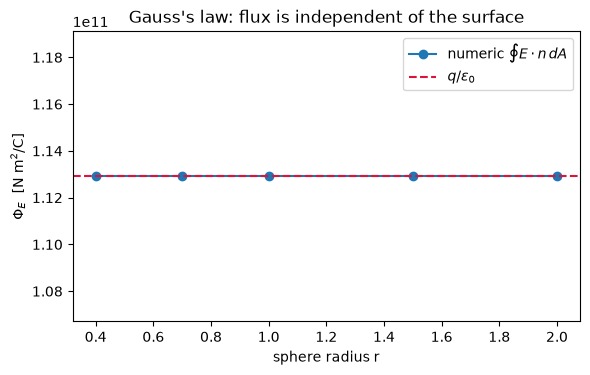

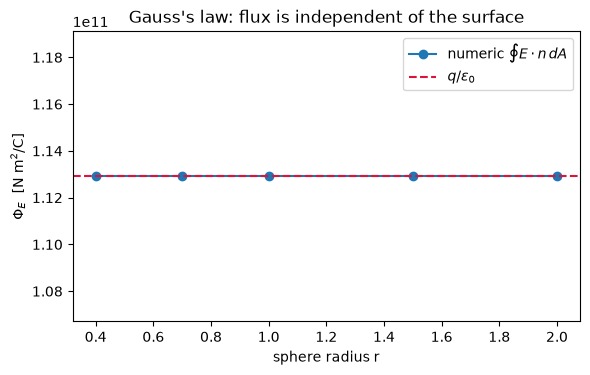

In [3]:
coulomb = lambda pts: eds.point_charge_field(q, np.zeros(3), pts)

flux_unit = flux_through_sphere(coulomb, 1.0)
print(f"numeric flux through r = 1 sphere : {flux_unit:.4e} N m^2/C")
print(f"q / eps0                          : {q / EPS0:.4e} N m^2/C")
print(f"ratio                             : {flux_unit / (q / EPS0):.6f}")

radii = np.array([0.4, 0.7, 1.0, 1.5, 2.0])
fluxes = np.array([flux_through_sphere(coulomb, r) for r in radii])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(radii, fluxes, "o-", label=r"numeric $\oint E \cdot n \, dA$")
ax.axhline(q / EPS0, color="crimson", ls="--", label=r"$q/\varepsilon_0$")
ax.set_xlabel("sphere radius r")
ax.set_ylabel(r"$\Phi_E$  [N m$^2$/C]")
ax.set_title("Gauss's law: flux is independent of the surface")
ax.legend()
fig.tight_layout()
fig

Gauss's law says *any* closed surface works, so the flux through the six flat faces of a cube centered on the charge must equal the flux through the sphere, even though the field on a face is neither constant nor exactly perpendicular to it. We sum $\mathbf{E} \cdot \hat{\mathbf{n}} \, dA$ over the six faces separately to see them conspire to the same total.

In [4]:
n_side, half = 60, 1.0
dA = (2.0 * half / n_side) ** 2

flux_cube = 0.0
for axis in range(3):
    for sign in (+1.0, -1.0):
        u = np.linspace(-half, half, n_side)
        U, V = np.meshgrid(u, u, indexing="ij")
        pts = np.zeros((n_side * n_side, 3))
        other = [a for a in range(3) if a != axis]
        pts[:, other[0]] = U.ravel()
        pts[:, other[1]] = V.ravel()
        pts[:, axis] = sign * half
        E = eds.point_charge_field(q, np.zeros(3), pts)
        n_hat = np.zeros_like(pts)
        n_hat[:, axis] = sign
        face_flux = np.sum(np.sum(E * n_hat, axis=1) * dA)
        flux_cube += face_flux
        print(f"face {'xyz'[axis]}{'+' if sign > 0 else '-'} flux : {face_flux: .4e} N m^2/C"
              f"  (q/(6 eps0) = {q / (6.0 * EPS0):.4e})")

print(f"\ntotal cube flux : {flux_cube:.4e} N m^2/C")
print(f"q / eps0        : {q / EPS0:.4e} N m^2/C")
print(f"ratio           : {flux_cube / (q / EPS0):.6f}")

face x+ flux :  1.8541e+10 N m^2/C  (q/(6 eps0) = 1.8823e+10)
face x- flux :  1.8541e+10 N m^2/C  (q/(6 eps0) = 1.8823e+10)
face y+ flux :  1.8541e+10 N m^2/C  (q/(6 eps0) = 1.8823e+10)
face y- flux :  1.8541e+10 N m^2/C  (q/(6 eps0) = 1.8823e+10)
face z+ flux :  1.8541e+10 N m^2/C  (q/(6 eps0) = 1.8823e+10)
face z- flux :  1.8541e+10 N m^2/C  (q/(6 eps0) = 1.8823e+10)

total cube flux : 1.1124e+11 N m^2/C
q / eps0        : 1.1294e+11 N m^2/C
ratio           : 0.984981


## Worked example 2 — the shell theorem

A uniformly charged shell of radius $R$ produces $\mathbf{E} = 0$ strictly inside and a pure Coulomb field outside. So a Gaussian sphere with radius below $R$ encloses no field lines (zero flux), while one above $R$ encloses all the charge (flux $= q/\varepsilon_0$).

In [5]:
R_shell = 1.0

pts, dA = sphere_points(0.5)
E_in = eds.shell_field(q, R_shell, pts)
flux_in = np.sum(np.sum(E_in * pts / 0.5, axis=1) * dA)
print(f"max |E| inside the shell    : {np.max(np.abs(E_in)):.3e}  (exact: 0)")
print(f"flux through r = 0.5 sphere : {flux_in:.3e} N m^2/C  (exact: 0)")

max |E| inside the shell    : 0.000e+00  (exact: 0)
flux through r = 0.5 sphere : 0.000e+00 N m^2/C  (exact: 0)


Sweeping the Gaussian sphere's radius through the shell radius shows the flux step from $0$ to $q/\varepsilon_0$ exactly at $r = R$: the jump in enclosed charge, not any change in the surface, produces the jump in flux.

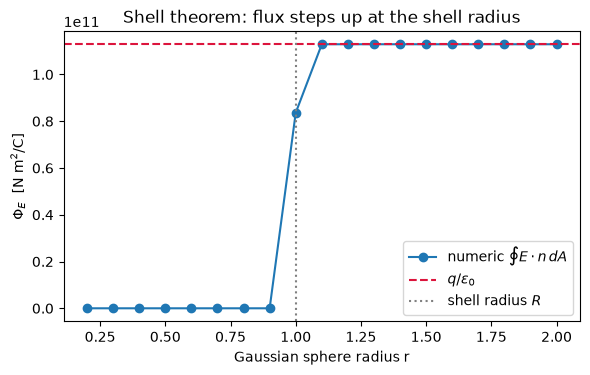

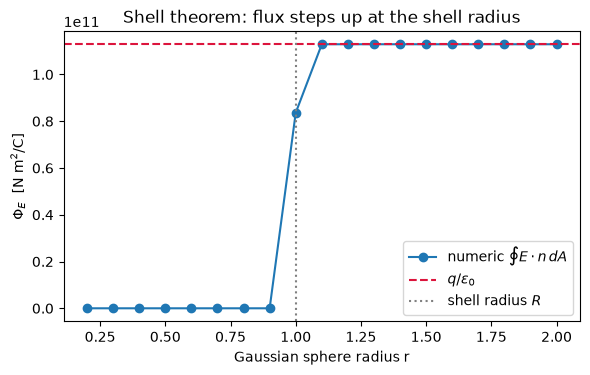

In [6]:
radii = np.linspace(0.2, 2.0, 19)
fluxes = []
for r in radii:
    pts, dA = sphere_points(r)
    E = eds.shell_field(q, R_shell, pts)
    fluxes.append(np.sum(np.sum(E * pts / r, axis=1) * dA))
fluxes = np.array(fluxes)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(radii, fluxes, "o-", label=r"numeric $\oint E \cdot n \, dA$")
ax.axhline(q / EPS0, color="crimson", ls="--", label=r"$q/\varepsilon_0$")
ax.axvline(R_shell, color="gray", ls=":", label=r"shell radius $R$")
ax.set_xlabel("Gaussian sphere radius r")
ax.set_ylabel(r"$\Phi_E$  [N m$^2$/C]")
ax.set_title("Shell theorem: flux steps up at the shell radius")
ax.legend()
fig.tight_layout()
fig

## Worked example 3 — divergence of E on a grid

The differential form of Gauss's law, $\nabla \cdot \mathbf{E} = \rho/\varepsilon_0$, says the divergence vanishes everywhere except at the charge itself, where it is singular (a delta function). We compute $\nabla \cdot \mathbf{E}$ by finite differences on a 3D grid that deliberately never lands on the charge, factor out $1/(4\pi\varepsilon_0)$ to keep the numbers readable, and plot a slice through the $z \approx 0$ plane. Away from the charge the divergence is zero to within a few percent of the local gradient scale $|\mathbf{E}|/r$ — that residual is finite-difference truncation error — while it blows up at the charge itself.

max |div E| for r > 0.25              : 2.722e+00
max |E|/r in the region (grad scale)  : 6.300e+01
ratio                                 : 4.32e-02


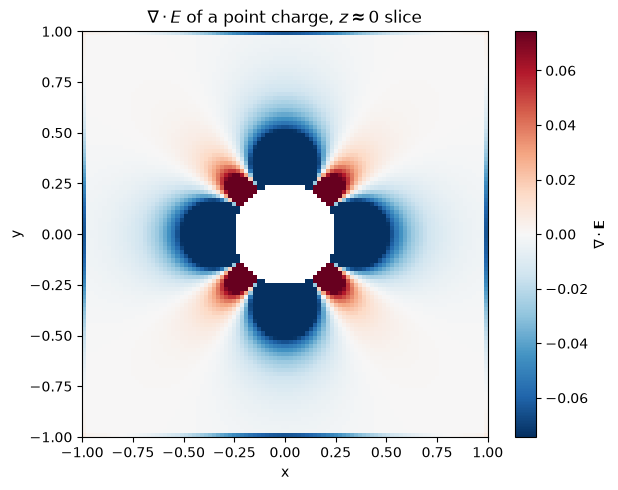

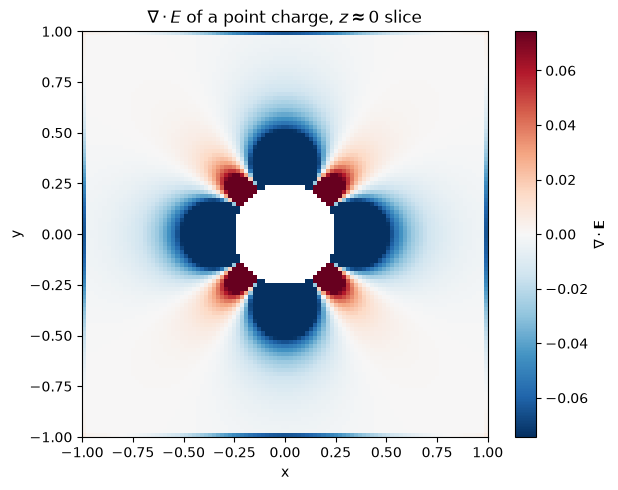

In [7]:
n = 100
xs = np.linspace(-1.0, 1.0, n)      # even point count -> no grid point sits on the charge
dx = xs[1] - xs[0]
X, Y, Z = np.meshgrid(xs, xs, xs, indexing="ij")
pts = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])

E = eds.point_charge_field(q, np.zeros(3), pts) * (4.0 * np.pi * EPS0)  # factor out 1/(4 pi eps0)
Exg, Eyg, Ezg = [c.reshape(n, n, n) for c in E.T]
divE = (np.gradient(Exg, dx, axis=0)
        + np.gradient(Eyg, dx, axis=1)
        + np.gradient(Ezg, dx, axis=2))

r = np.sqrt(X**2 + Y**2 + Z**2)
mask = r > 0.25
Emag = np.sqrt(Exg**2 + Eyg**2 + Ezg**2)
div_max = np.max(np.abs(divE[mask]))
grad_scale = np.max(Emag[mask] / r[mask])
print(f"max |div E| for r > 0.25              : {div_max:.3e}")
print(f"max |E|/r in the region (grad scale)  : {grad_scale:.3e}")
print(f"ratio                                 : {div_max / grad_scale:.2e}")

iz0 = np.argmin(np.abs(xs))          # slice with z closest to 0
div_slice = np.where(mask[:, :, iz0], divE[:, :, iz0], np.nan)
vlim = np.nanpercentile(np.abs(div_slice), 90)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(div_slice.T, origin="lower", extent=[-1, 1, -1, 1],
               cmap="RdBu_r", vmin=-vlim, vmax=vlim)
fig.colorbar(im, ax=ax, label=r"$\nabla \cdot \mathbf{E}$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(r"$\nabla \cdot E$ of a point charge, $z \approx 0$ slice")
fig.tight_layout()
fig

## Worked example 4 — curl E = 0 for a static dipole

A static charge distribution (here a dipole built from $+q$ and $-q$) produces a curl-free field: that is what lets us write $\mathbf{E} = -\nabla V$ at all. We compute all three components of $\nabla \times \mathbf{E} = (\partial_y E_z - \partial_z E_y, \; \partial_z E_x - \partial_x E_z, \; \partial_x E_y - \partial_y E_x)$ by finite differences on a grid. Each of those terms is of order $|\mathbf{E}|/r$ individually, and for a static field they cancel: away from the charges the curl comes out to only a few percent of the local gradient scale (finite-difference truncation error), and it is exactly zero in the continuum.

max |curl E| away from charges        : 5.075e-01
max |E|/r in the region (grad scale)  : 2.195e+01
ratio                                 : 2.31e-02


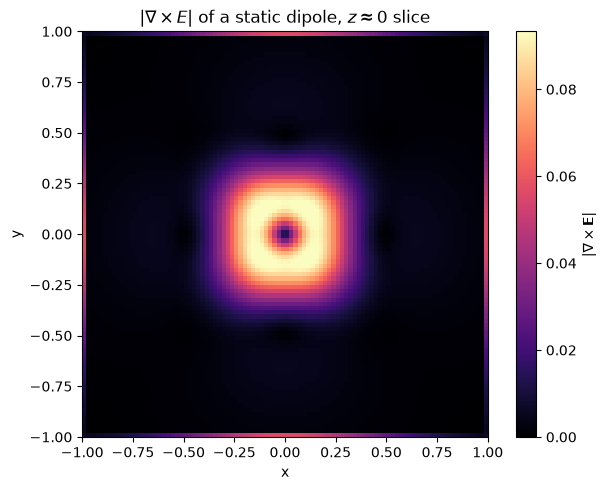

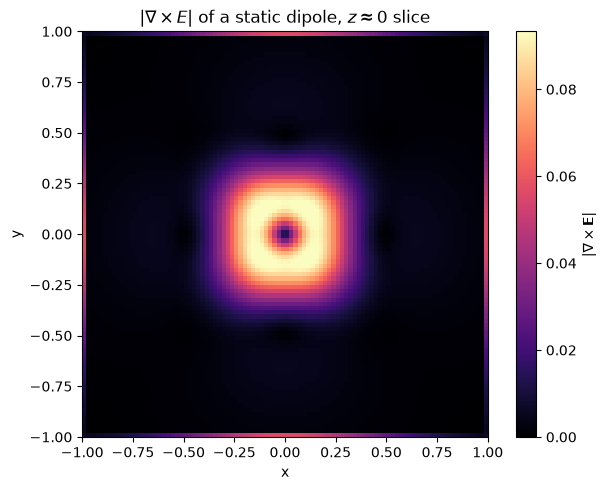

In [8]:
qd, d = 1.0, 0.5
charges = [(qd, np.array([0.0, 0.0,  d])),
           (-qd, np.array([0.0, 0.0, -d]))]

n = 96
xs = np.linspace(-1.0, 1.0, n)      # even count -> grid misses both charges
dx = xs[1] - xs[0]
X, Y, Z = np.meshgrid(xs, xs, xs, indexing="ij")
pts = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])

E = eds.superpose(charges, pts)[0] * (4.0 * np.pi * EPS0)  # factor out 1/(4 pi eps0)
Exg, Eyg, Ezg = [c.reshape(n, n, n) for c in E.T]

curl_x = np.gradient(Eyg, dx, axis=2) - np.gradient(Ezg, dx, axis=1)
curl_y = np.gradient(Ezg, dx, axis=0) - np.gradient(Exg, dx, axis=2)
curl_z = np.gradient(Exg, dx, axis=1) - np.gradient(Eyg, dx, axis=0)
curl_mag = np.sqrt(curl_x**2 + curl_y**2 + curl_z**2)
Emag = np.sqrt(Exg**2 + Eyg**2 + Ezg**2)

r_charge = np.minimum(np.sqrt(X**2 + Y**2 + (Z - d)**2),
                      np.sqrt(X**2 + Y**2 + (Z + d)**2))
mask = r_charge > 0.4               # stay away from the singular points
curl_max = np.max(curl_mag[mask])
grad_scale = np.max(Emag[mask] / r_charge[mask])
print(f"max |curl E| away from charges        : {curl_max:.3e}")
print(f"max |E|/r in the region (grad scale)  : {grad_scale:.3e}")
print(f"ratio                                 : {curl_max / grad_scale:.2e}")

iz0 = np.argmin(np.abs(xs))          # equatorial slice z closest to 0
curl_slice = np.where(mask[:, :, iz0], curl_mag[:, :, iz0], np.nan)
vmax = np.nanpercentile(curl_slice, 99)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(curl_slice.T, origin="lower", extent=[-1, 1, -1, 1],
               cmap="magma", vmin=0.0, vmax=vmax)
fig.colorbar(im, ax=ax, label=r"$|\nabla \times \mathbf{E}|$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(r"$|\nabla \times E|$ of a static dipole, $z \approx 0$ slice")
fig.tight_layout()
fig

Finally, a picture of the dipole field itself: the field lines of $\mathbf{E}$ overlayed on the equipotential surfaces of $V$. The lines leave $+q$ and enter $-q$, they never cross, and they always meet the equipotentials at right angles — the geometric face of $\mathbf{E} = -\nabla V$.

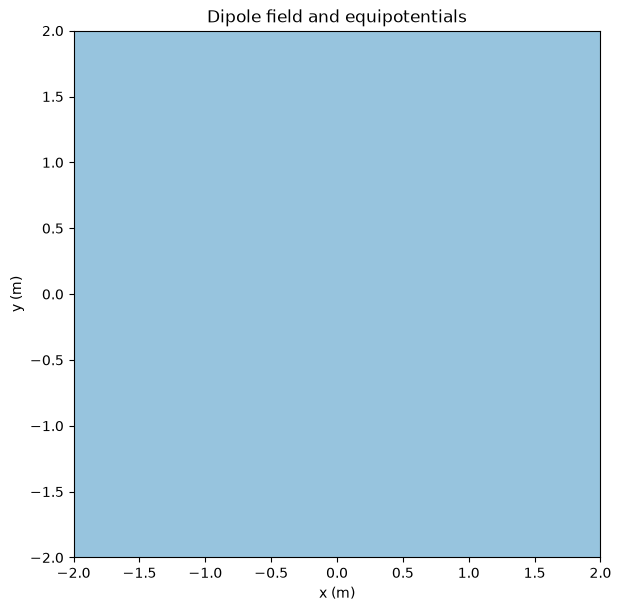

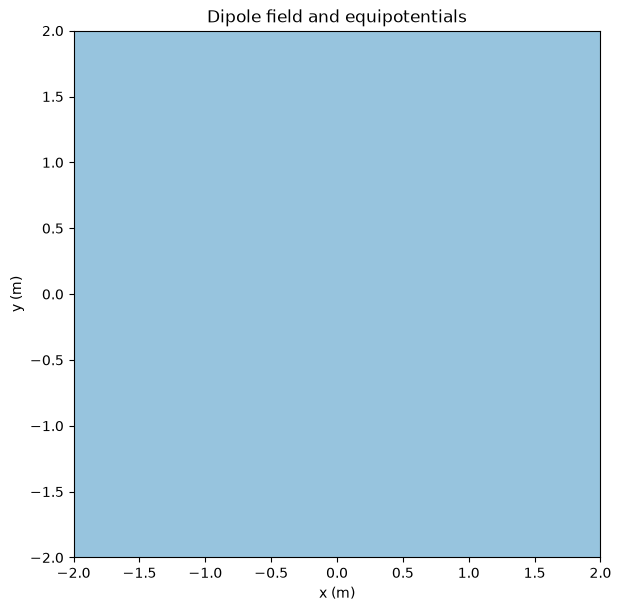

In [9]:
def dipole_field_func(x, y):
    pts = np.column_stack([x.ravel(), y.ravel(), np.zeros(x.size)])
    E, _ = eds.superpose(charges, pts)
    return E[:, 0].reshape(x.shape), E[:, 1].reshape(x.shape)

def dipole_potential_func(x, y):
    pts = np.column_stack([x.ravel(), y.ravel(), np.zeros(x.size)])
    _, V = eds.superpose(charges, pts)
    return V.reshape(x.shape)

fig, ax = eds.plot_field_and_potential(dipole_field_func, dipole_potential_func,
                                       extent=2.0, title="Dipole field and equipotentials")
fig

## Exercises

1. **Flux and surface shape (conceptual).** In Worked example 2 the field on the flat faces of the cube is weaker than on the enclosing sphere and not perpendicular to the faces, yet the total flux is identical. Explain, using solid angles or the $1/r^2$ law, why the shape of the Gaussian surface cannot matter.

2. **Locating the shell (coding).** Using `eds.shell_field` and the `sphere_points` / `flux_through_sphere` helpers, compute the flux divided by $\varepsilon_0$ through spheres of radius $0.9$ and $1.1$ around a shell of radius $1.0$ carrying charge $q = 2$. Use the two flux values to determine the enclosed charge in each case, then shrink the radius step until you can pin down the shell radius to within $0.01$.

3. **Gauss with a smeared charge (coding).** Build a smooth charge density on a 2D grid with `eds.gaussian_delta`, solve $-\varepsilon_0 \nabla^2 V = \rho$ with `eds.poisson_solve(rho, dx)`, recover the field with `eds.electric_field_from_potential`, and check that the flux of $\mathbf{E}$ through the boundary of the grid matches the total enclosed charge divided by $\varepsilon_0$. How does the match improve when you double the grid size?

4. **Curl of the shell field (coding).** Repeat the finite-difference curl computation of Worked example 4 for `eds.shell_field` with $q = 1$, $R = 1$, on a grid that avoids the shell. Verify that $\nabla \times \mathbf{E} \approx 0$ both inside and outside, and explain why the field can jump discontinuously at $r = R$ while its curl still vanishes away from the surface.

5. **From Faraday to displacement current (conceptual).** A charging parallel-plate capacitor carries conduction current $I$ in the wires but none between the plates. Show that Ampère's law without the displacement current term gives contradictory values for $\oint \mathbf{B} \cdot d\boldsymbol{\ell}$ depending on which surface you span with the loop, and explain how the $\mu_0 \varepsilon_0 \, \partial \mathbf{E}/\partial t$ term repairs the inconsistency. What field between the plates plays the role of the current?